In [3]:
import seaborn as sns
import pandas as pd
import csv
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from utils import significance,adjust_box_widths
from matplotlib.patches import PathPatch

In [4]:
df = pd.read_csv('ScoreIntzones_merged.csv')
df = df.drop('Cups Hab', 1)
print(df.loc[df['Control']=='y',:])

    Group  Cups LTM       LTM Control
0       1  0.029126  0.066667       y
3       4  0.028058 -0.089552       y
5       6  0.105000 -0.078014       y
10     11 -0.011628 -0.214286       y
15     16  0.077844  0.078534       y
16     17  0.143077  0.102041       y
17     18 -0.030667  0.118000       y
19     20  0.103333  0.025333       y
23     24  0.012667 -0.069333       y
24     25 -0.088000  0.056000       y
27     28  0.084667 -0.079333       y
28     29  0.115385  0.054902       y
29     30  0.041064 -0.148814       y
30     31 -0.165333 -0.150335       y
32     33  0.087719  0.000000       y
33     34  0.034000  0.224252       y
34     35  0.200667 -0.031560       y
35     36 -0.052667  0.192818       y
38     39 -0.129000 -0.197765       y
39     40  0.151000 -0.016904       y
42     43 -0.085533 -0.001126       y
48     49  0.012913  0.166667       y


/var/folders/b7/k9l5l5ss13d27wd57vb8fq4w0000gn/T/ipykernel_76338/623465510.py:2: FutureWarning: In a future version of pandas all arguments of DataFrame.drop except for the argument 'labels' will be keyword-only.
  df = df.drop('Cups Hab', 1)


In [5]:
data = []

for el in df.drop("Group",axis=1).drop("Control",axis=1):
    for i,val in enumerate(df[el]):
        data.append([el,val,df.iloc[i].get('Control')])
        
newdf = (pd.DataFrame(data,columns=['Experimental Condition','Left preference','control']))
#print(newdf)

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


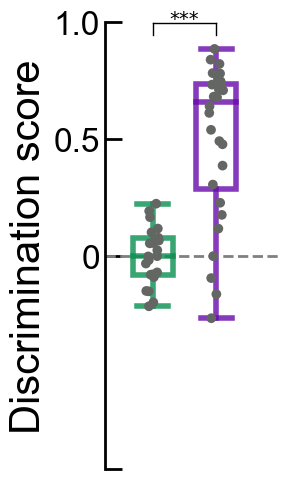

In [7]:
PROPS = {
    'boxprops':{'facecolor':'none', 'edgecolor':'mediumblue','alpha': 0.8},
    'medianprops':{'color':'cornflowerblue','alpha': 0.8},
    'whiskerprops':{'color':'cornflowerblue','alpha': 0.8},
    'capprops':{'color':'cornflowerblue','alpha': 0.8}
}

text_boxplot = ['','****']
colors = ["C7","C7"]
colors_boxplot = ['#078f4f', "#680aab"]

text_boxplot = ['','***']
colors = ["#a2a6a3","#a2a6a3"]
colors = ["#646664","#646664"]
colors_boxplot = ['#078f4f', "#680aab"]

ax = sns.stripplot(
    data=newdf,
    x='Experimental Condition',
    y='Left preference',
    hue='control',
    size=7,
    palette=colors,
    jitter=0.09,
    dodge=True
)


locs = ["upper left"]
boxplot = sns.boxplot(
    data=newdf,
    x='Experimental Condition',
    y='Left preference',
    hue='control',
    palette=colors_boxplot,
    fliersize=0,
    linewidth=4,
    **PROPS
)
plt.axhline(linewidth=2, color='grey',ls='--')

data_ratio = 0.4016222222466667


ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.spines['bottom'].set_visible(False)
ax.spines['left'].set_linewidth(2)

#CHANGE BOXPLOT STYLE

box_patches = [patch for patch in boxplot.patches if type(patch) == matplotlib.patches.PathPatch]
if len(box_patches) == 0:  # in matplotlib older than 3.5, the boxes are stored in ax2.artists
    box_patches = boxplot.artists
    
num_patches = len(box_patches)
lines_per_boxplot = len(boxplot.lines) // num_patches

for i, patch in enumerate(box_patches):
    
    col = colors_boxplot[i%2]
    patch.set_edgecolor(col)
    patch.set_facecolor('None')
    
    for line in boxplot.lines[i * lines_per_boxplot: (i + 1) * lines_per_boxplot]:
        line.set_color(col)
        
        
#END CHANGE BOXPLOT STYLE

#handles, labels = ax.get_legend_handles_labels()
#l = plt.legend(handles[0:2], ["", ""],loc=2)
plt.legend([],[], frameon=False)

ax.set_xticklabels(['Cups','Social'], fontsize = 26)
ax.spines['bottom'].set_linewidth(2)
ax.spines['left'].set_linewidth(2)

#ax.text(-0.3,1.15,'Upper', fontsize = 26)
#ax.text(0.9,1.15,'CS-', fontsize = 26)

ax.set_xlabel("",fontsize=20)
ax.set_ylabel('Discrimination score', fontsize = 26)


ax.set_ylim([-0.5999,1.1])
ax.set_xlim([-0.5,1.6])

ax.set_yticks([0.5,1], fontname='Arial')
ax.set_xlabel("",fontsize=20)
ax.set_ylabel('Discrimination score', fontsize = 30, fontname='Arial')

ax.set_yticks([-0.90999,0,0.5,1], fontname='Arial')
ax.set_yticklabels(['','0','0.5','1.0'],fontname='Arial')

ax.set_ylim([-0.90999,1])
ax.set_xlim([0.5,1.6])
significance(ax,1,data_ratio,newdf.loc[newdf['control']=='n']['Left preference'].max()+0.01,text=text_boxplot[1],offset=0.13,whisker=0.08)


fig = ax.get_figure()
adjust_box_widths(fig, 0.8)
fig.set_size_inches(5.1,4.9)
ax.tick_params(axis='y', which='major', direction='in',length=12, labelsize=24, width=2)
ax.set_xticks([])

plt.title("", fontsize=24,y=1.05)

fig = ax.get_figure()

adjust_box_widths(fig, 0.8)
fig.set_size_inches(3,4.9)
ax.tick_params(axis='y', which='major', labelsize=24)

plt.tight_layout()
fig.tight_layout()
fig.savefig("Fig_ScoresIntzones_noCups.jpg",dpi=500,bbox_inches='tight')
plt.savefig('Fig_ScoresIntzones_noCups.eps', format='eps')

